# Team A7 - Descriptive question (Neighborhood PCA)


**Descriptive Question:** Between 2004–06 and 2014–16, did 2-bedroom asking rents rise faster in San Francisco neighborhoods that started in the cheapest third than in those that started in the priciest third, and did listings in those cheaper neighborhoods shift toward studios and 1-bedrooms?

**Context:** SF planning and tenant groups deciding where to aim rent-stabilization and affordability outreach, instead of spreading it citywide.

**Methodolody:** PCA lets the data show which neighborhoods actually behave alike. If the cheapest third is not one group, outreach should be aimed at specific neighborhoods, not "the cheap ones".


## 1. Setup and data

In [10]:
# set up
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.linalg import subspace_angles
from scipy.stats import spearmanr
try:                                  
    from adjustText import adjust_text
except ImportError:
    adjust_text = None

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')
THIRD_COLORS = {'cheapest': '#d95f02', 'middle': '#7570b3', 'priciest': '#1b9e77'}

BASE = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2022/2022-07-05/'

In [11]:
# load data
rent = pd.read_csv(BASE + 'rent.csv')
print(f'{rent.shape[0]:,} rows × {rent.shape[1]} columns')
rent.head()

200,796 rows × 17 columns


,post_id,date,year,nhood,city,county,price,beds,baths,sqft,room_in_apt,address,lat,lon,title,descr,details
0,pre2013_134138,20050111,2005,alameda,alameda,alameda,1250,2.0,2.0,NaN,0,NaN,NaN,NaN,$1250 / 2br - 2BR/2BA 1145 ALAMEDA DE LAS PU...,NaN,NaN
1,pre2013_135669,20050126,2005,alameda,alameda,alameda,1295,2.0,NaN,NaN,0,NaN,NaN,NaN,$1295 / 2br - Walk the Beach! 1 FREE MONTH + $...,NaN,NaN
2,pre2013_127127,20041017,2004,alameda,alameda,alameda,1100,2.0,NaN,NaN,0,NaN,NaN,NaN,$1100 / 2br - cottage,NaN,NaN
3,pre2013_68671,20120601,2012,alameda,alameda,alameda,1425,1.0,NaN,735.0,0,NaN,NaN,NaN,$1425 / 1br - 735ft² - BEST LOCATION SOUTHSHOR...,NaN,NaN
4,pre2013_127580,20041021,2004,alameda,alameda,alameda,890,1.0,NaN,NaN,0,NaN,NaN,NaN,"$890 / 1br - Classy ""Painted Lady"" VICTORIAN -...",NaN,NaN


In [12]:
summary = pd.DataFrame({
    'dtype': rent.dtypes.astype(str),
    'non_null': rent.notna().sum(),
    'unique': rent.nunique(),
    'example': rent.iloc[0],
})
summary

,dtype,non_null,unique,example
post_id,object,200796,200796,pre2013_134138
date,int64,200796,922,20050111
year,int64,200796,19,2005
nhood,object,200796,167,alameda
city,object,200796,104,alameda
county,object,199402,10,alameda
price,int64,200796,4212,1250
beds,float64,194188,11,2.0
baths,float64,42675,15,2.0
sqft,float64,64679,2808,NaN


each row = 1 Craigslist rental listing in the Bay Area. 

We are focusing on column `year`, `nhood` (the neighborhood label the poster chose), `city`, `price` (monthly asking rent, $), `beds`, `sqft` and `room_in_apt`. 

and since there is **no income column**, so "lower-income" has to be approximated (later on)




## 2. EDA

### 2.1 Missing values

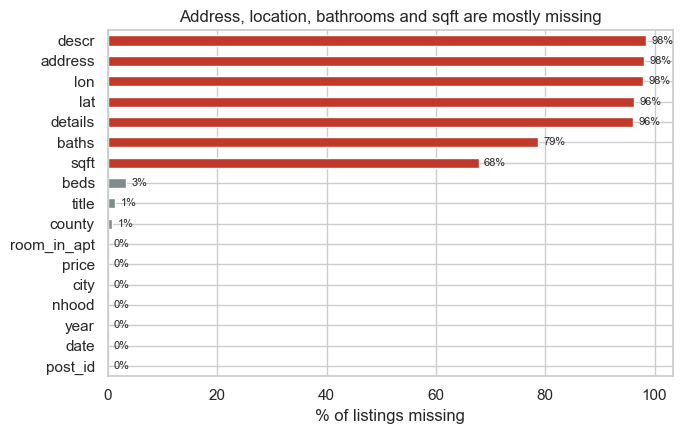

In [13]:
miss = (rent.isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
miss.plot.barh(ax=ax, color=['#c0392b' if v > 50 else '#7f8c8d' for v in miss])
ax.set_xlabel('% of listings missing'); ax.set_title('Address, location, bathrooms and sqft are mostly missing')
for i, v in enumerate(miss):
    ax.text(v + 1, i, f'{v:.0f}%', va='center', fontsize=8)
plt.tight_layout(); plt.show()

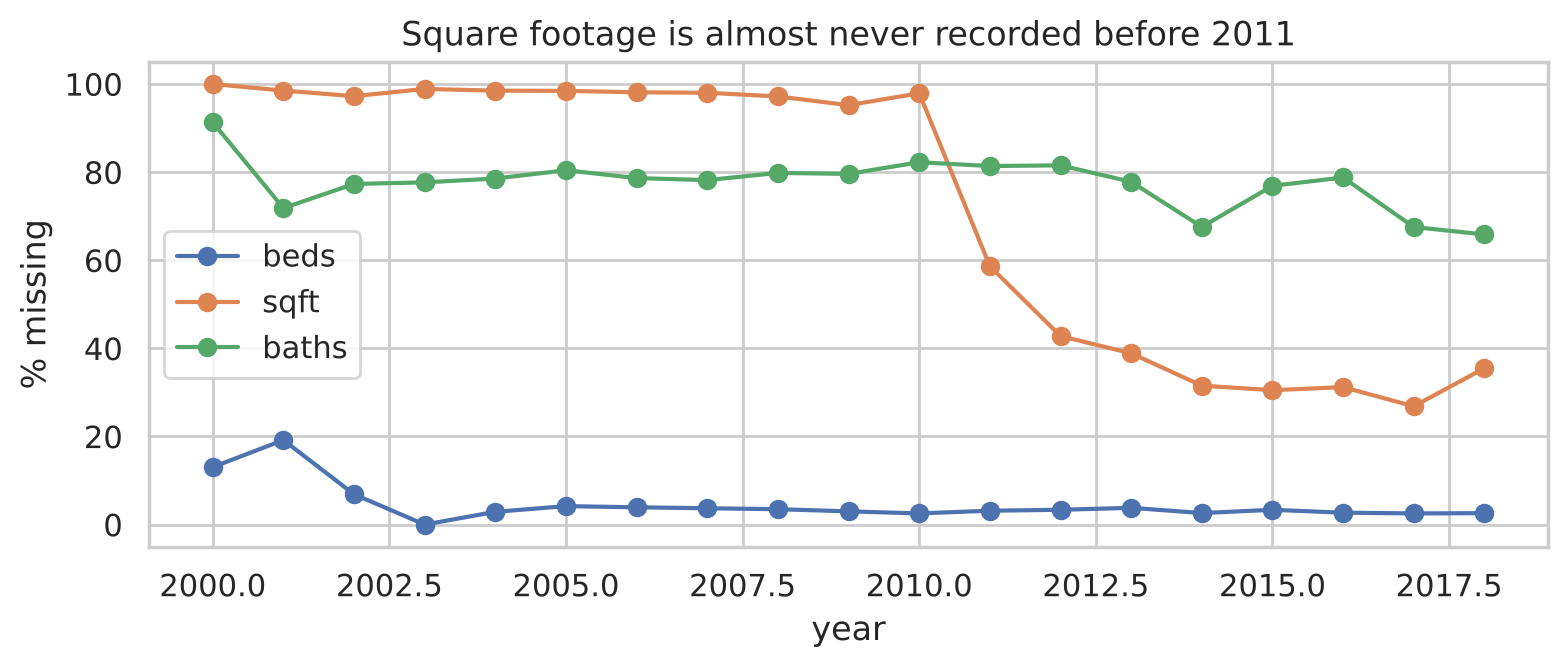

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
beds,13.0,19.2,6.9,0.0,2.9,4.2,3.9,3.7,3.5,3.0,2.5,3.1,3.4,3.8,2.6,3.4,2.7,2.5,2.6
sqft,100.0,98.5,97.3,98.9,98.5,98.4,98.1,98.0,97.2,95.2,97.9,58.6,42.8,38.9,31.5,30.5,31.2,26.8,35.5
baths,91.3,71.8,77.3,77.7,78.5,80.4,78.6,78.2,79.8,79.6,82.2,81.4,81.5,77.8,67.6,76.9,78.8,67.5,65.9


: 

: 

: 

: 

: 

... (3 outputs left out)

: 

: 

: 

: 

In [5]:
miss_year = rent.groupby('year')[['beds', 'sqft', 'baths']].apply(lambda d: d.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(8, 3.5))
miss_year.plot(ax=ax, marker='o')
ax.set_ylabel('% missing'); ax.set_title('Missing Value by year') # square footage is almost never recorded before 2011
plt.tight_layout(); plt.show()
miss_year.round(1).T

Address + latitude/longitude + description and details are 96–98% missing =  can't locate listing or interprete their description

Bathrooms are 79% missing (under 4% of listings from 2003 onward) + square footage are 95–100% missing (every year before 2011, then 27–59% after) 

so unit size is measured by  # of bedrooms, since we dont have square feet data

### 2.2 How many listings, when and where

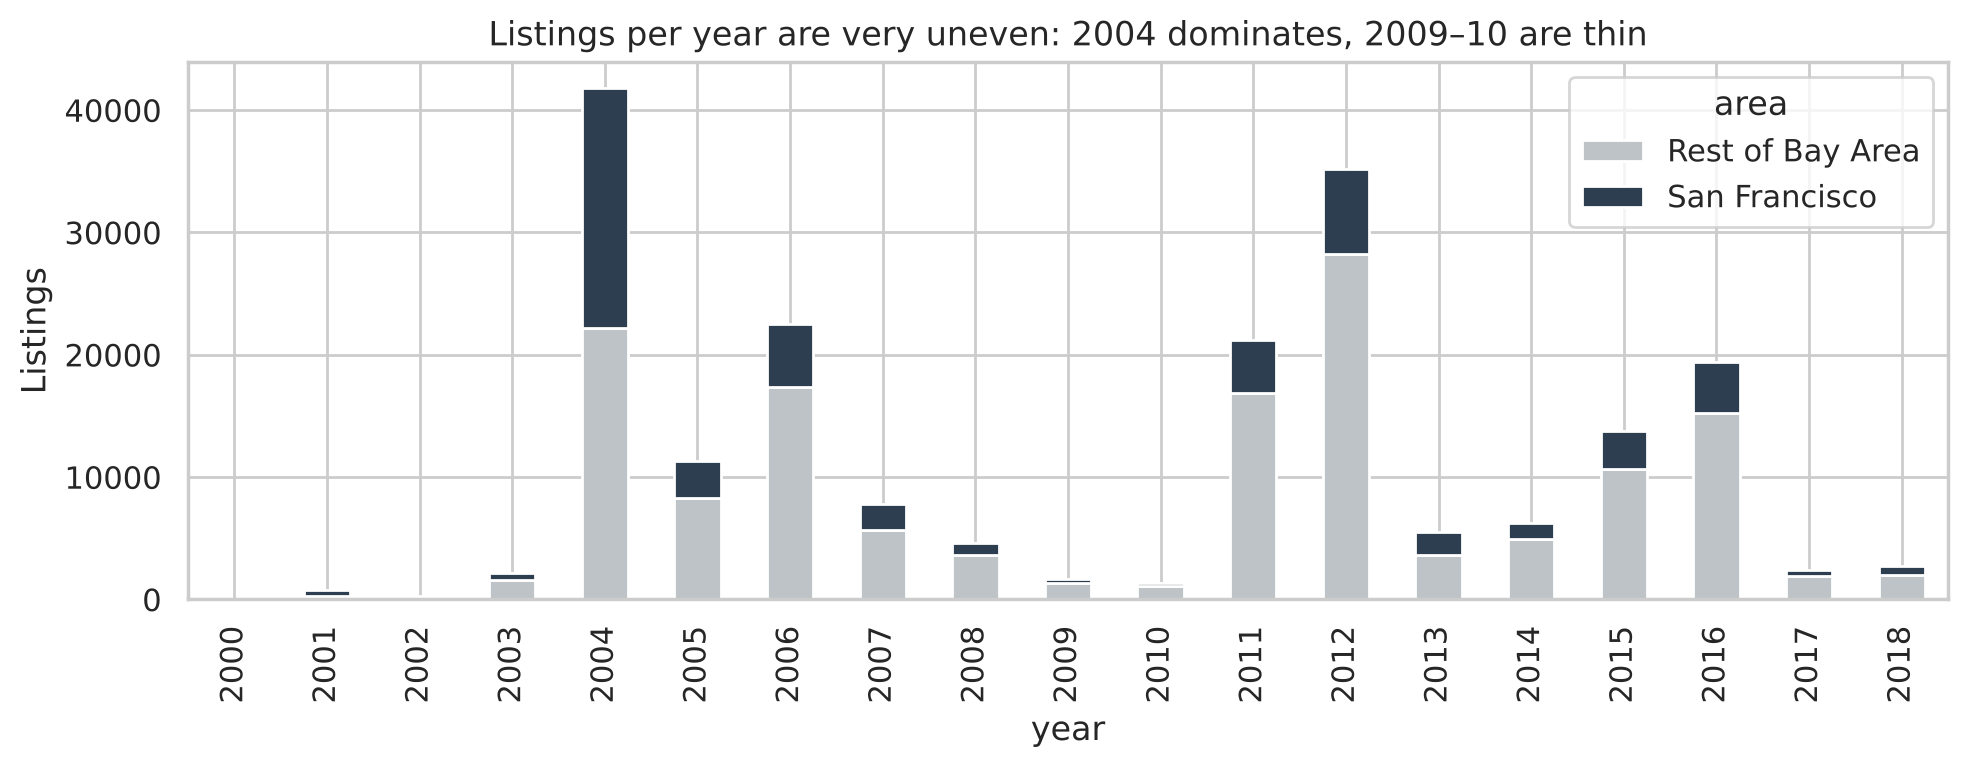

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
area,,,,,,,,,,,,,,,,,,,
Rest of Bay Area,12,304,143,1620,22193,8297,17346,5675,3650,1320,1123,16860,28258,3607,4907,10692,15209,1876,1974
San Francisco,11,431,148,521,19654,2988,5187,2129,930,347,257,4370,6948,1888,1324,3109,4191,530,767


: 

: 

: 

: 

: 

... (3 outputs left out)

: 

: 

: 

: 

In [6]:
#  listings per year, in sf vs rest of bay area 
rent['area'] = np.where(rent.city == 'san francisco', 'San Francisco', 'Rest of Bay Area')
per_year = rent.pivot_table(index='year', columns='area', values='price', aggfunc='size').fillna(0)
ax = per_year.plot.bar(stacked=True, figsize=(10, 4), color=['#bdc3c7', '#2c3e50'])
ax.set_ylabel('Listings'); ax.set_title('Listing in sf vs rest of bay area by year') # listings per year are very uneven = 2004 dominates & 2009–10 are thin
plt.tight_layout(); plt.show()
per_year.astype(int).T

In [ ]:
# 2 data collection method, checking for differences
rent['source'] = np.where(rent.post_id.str.startswith('pre2013'), 'pre2013 archive ids', 'numeric ids (2013+)')
sf_raw = rent[rent.city == 'san francisco'].copy()
eras = pd.crosstab(sf_raw.year, sf_raw.source)
eras['distinct_days'] = sf_raw.groupby('year').date.nunique()
eras.T

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
source,,,,,,,,,,,,,,,,,,,
numeric ids (2013+),0,0,0,0,0,0,0,0,0,0,0,0,0,1886,1324,3109,4191,530,767
pre2013 archive ids,11,431,148,521,19654,2988,5187,2129,930,347,257,4370,6948,2,0,0,0,0,0
distinct_days,1,8,3,11,174,118,98,45,28,13,8,56,104,35,27,38,59,24,26


: 

: 

: 

: 

: 

... (3 outputs left out)

: 

: 

: 

: 

In [8]:
# by county
rent.county.value_counts(dropna=False).to_frame('listings')
# sf is the largest county = 55,730 listings, 28%


,listings
county,
san francisco,55730
santa clara,41023
alameda,25630
san mateo,25238
contra costa,13605
sonoma,12422
marin,11237
santa cruz,8590
solano,3742


: 

: 

: 

: 

: 

... (3 outputs left out)

: 

: 

: 

: 

inconsistent sampling -->  2004 alone has 41,847 Bay Area listings (19,654 in San Francisco), while SF has only 347 listings in 2009 and 257 in 2010. 

inconsitent scaping --> scaping day per year ranges from 1 to 174, so a "year" can mean one day of listings or most of the year

two collection method -->  two end periods (2004–06 and 2014–16) come from different methods


going with comparing pooled periods and not single years

### 2.3 Prices

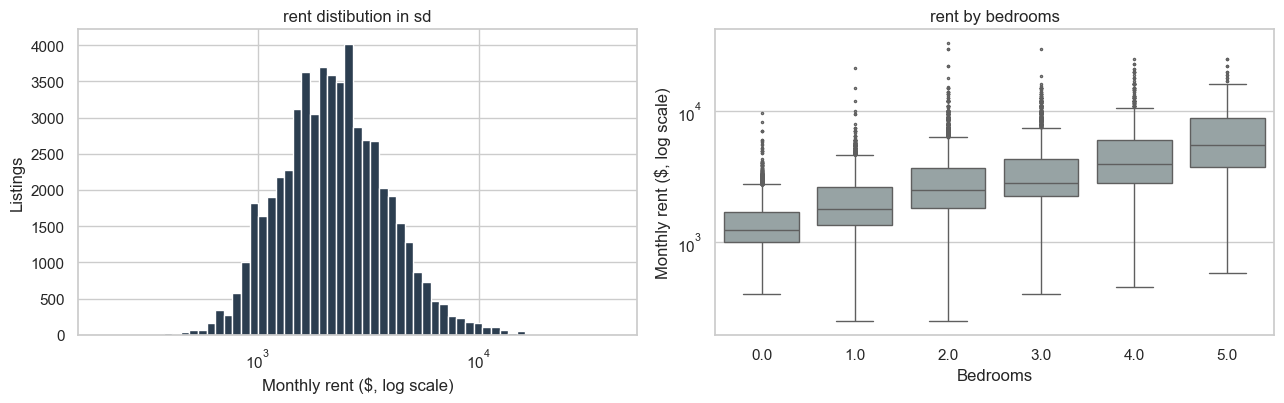

,count,mean,std,min,0.1%,0.5%,1%,50%,99%,99.5%,99.9%,max
SF price ($),55730.0,2603.0,1784.0,225.0,450.0,600.0,695.0,2195.0,9750.0,11996.0,16636.0,33000.0


: 

: 

: 

: 

: 

... (3 outputs left out)

: 

: 

: 

: 

In [ ]:
# price distribution in sf, and by bedrooms
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.logspace(np.log10(200), np.log10(40000), 60)
axes[0].hist(sf_raw.price, bins=bins, color='#2c3e50')
axes[0].set_xscale('log'); axes[0].set_xlabel('Monthly rent ($, log scale)'); axes[0].set_ylabel('Listings')
axes[0].set_title('rent distibution in sd') # right-skewed, outliers at both ends
sns.boxplot(data=sf_raw[sf_raw.beds <= 5], x='beds', y='price', ax=axes[1], color='#95a5a6', fliersize=1.5)
axes[1].set_yscale('log'); axes[1].set_xlabel('Bedrooms'); axes[1].set_ylabel('Monthly rent ($, log scale)')
axes[1].set_title('rent by bedrooms') # median rent increases with number of bedrooms, a lot of overlap + outliers
plt.tight_layout(); plt.show()
sf_raw.price.describe(percentiles=[.001, .005, .01, .5, .99, .995, .999]).round(0).to_frame('SF price ($)').T

In [10]:
# outliers
cols = ['year', 'nhood', 'beds', 'price', 'title']
print('Cheapest 2-bedroom listings:')
display(sf_raw[sf_raw.beds == 2].nsmallest(5, 'price')[cols])
print('Most expensive 1-bedroom listings:')
display(sf_raw[sf_raw.beds == 1].nlargest(5, 'price')[cols])

Cheapest 2-bedroom listings:


,year,nhood,beds,price,title
132924,2013,san francisco,2.0,250,Big beautiful home for rent to own
132969,2013,san francisco,2.0,250,Home for rent to own well maintained
84923,2011,nob hill,2.0,400,"$400 / 2br - Rarely Avail. 2BR, $4500 Jan & Fe..."
133500,2012,san francisco,2.0,400,$400 / 2br - Home for rent
3302,2011,bayview,2.0,425,$425 / 2br - Houses For Affordable Budget


Most expensive 1-bedroom listings:


,year,nhood,beds,price,title
105969,2011,pacific heights,1.0,21500,$21500 / 1br - One Bedroom Apt in Art Deco Bui...
178784,2016,SOMA / south beach,1.0,15000,Oca 25 ***LIVE/WORK LOFT HISTORIC BUILDING*** ...
67445,2015,marina / cow hollow,1.0,12000,COW HOLLOW Single family home with an in law u...
85150,2006,nob hill,1.0,10000,"$10000 / 1br - Park lane..Penthouse- 1bedroom,..."
42025,2005,financial district,1.0,9500,$9500 / 1br - 1 BR + Den + Garage Downtown *PH...


: 

: 

... (6 outputs left out)

: 

: 

: 

: 

since it is rk --> remove prices outside the 0.5–99.5% range for each year × bedroom group 

### 2.4 Unit sizes over time

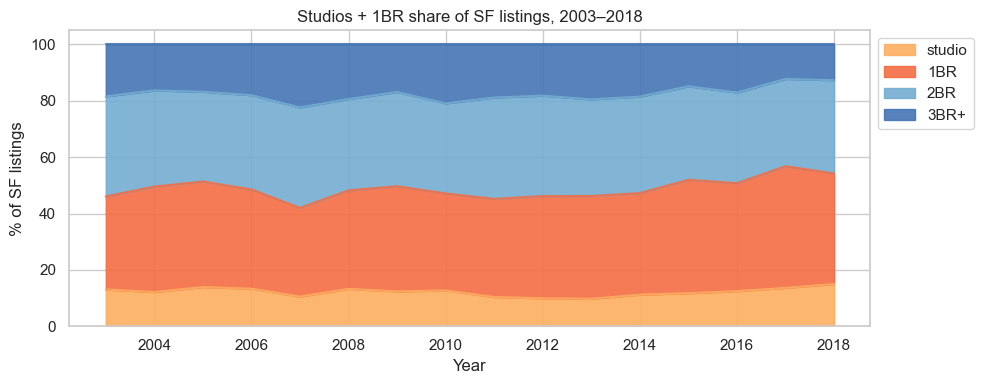

year,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
size,,,,,,,,,,,,,,,,
studio,13.1,12.1,13.9,13.3,10.5,13.3,12.3,12.7,10.4,9.9,9.7,11.2,11.7,12.4,13.6,15.0
1BR,33.0,37.5,37.5,35.2,31.5,35.0,37.3,34.4,34.8,36.3,36.5,36.1,40.2,38.3,43.2,39.2
2BR,35.5,34.1,31.8,33.5,35.6,32.4,33.4,32.0,36.0,35.6,34.3,34.2,33.2,32.2,31.0,33.1
3BR+,18.4,16.3,16.8,18.0,22.4,19.4,16.9,20.9,18.8,18.2,19.5,18.5,14.8,17.0,12.2,12.7


: 

: 

: 

: 

: 

... (3 outputs left out)

: 

: 

: 

: 

In [12]:
# type of bedrooms, share of listings by year
mix = (sf_raw.dropna(subset=['beds'])
             .assign(size=lambda d: d.beds.clip(upper=3).map({0: 'studio', 1: '1BR', 2: '2BR', 3: '3BR+'}))
             .pivot_table(index='year', columns='size', values='price', aggfunc='size')
             [['studio', '1BR', '2BR', '3BR+']])
mix_share = mix.div(mix.sum(axis=1), axis=0) * 100
ax = mix_share.loc[2003:].plot.area(figsize=(10, 4), color=['#fdae61', '#f46d43', '#74add1', '#4575b4'], alpha=.9)
ax.set_ylabel('% of SF listings'); ax.set_xlabel('Year')
ax.set_title('Studios + 1BR share of SF listings, 2003–2018')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
mix_share.loc[2003:].round(1).T

studios and 1-bedrooms = between 42% and 51% of SF listings each year through 2014 --> rose to 57% in 2017 & 54% in 2018 

3BR+ fell from 15–22% (through 2016) to about 12% in 2017–18

shift toward small units happens after 2015 --> 2014–16 may only catch the start of this transition

### 2.5 Rent over time, holding unit size fixed

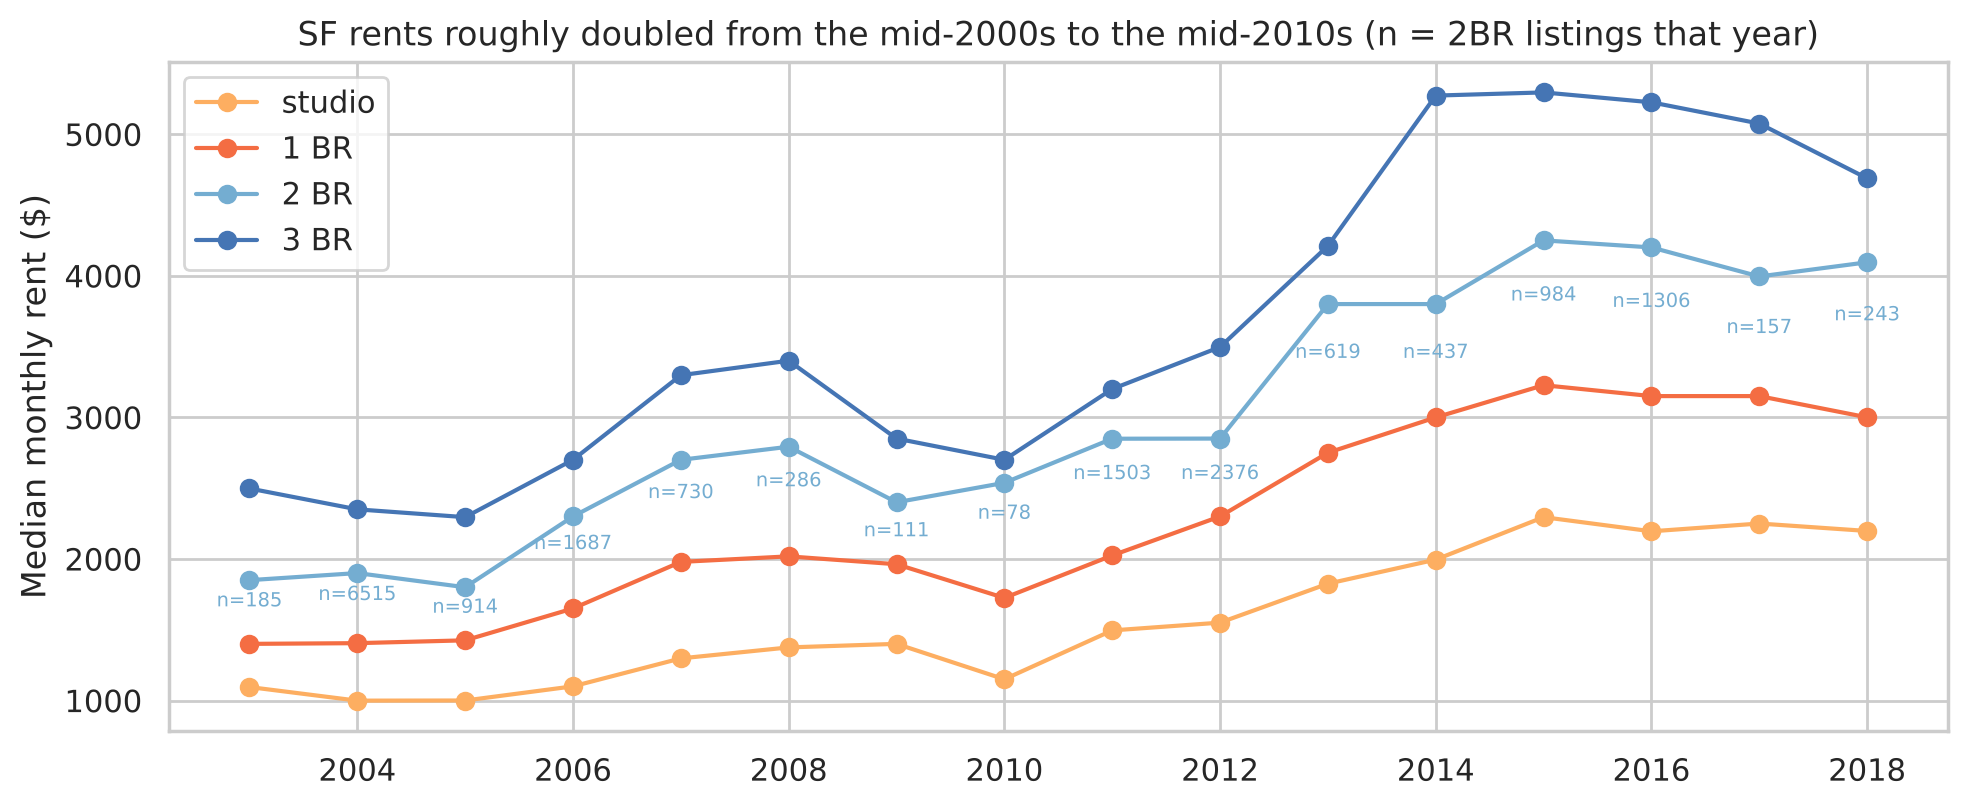

: 

: 

: 

: 

: 

: 

... (2 outputs left out)

: 

: 

: 

: 

In [12]:
# median rent by year and bedrooms, with sample size 
sf_b = sf_raw[sf_raw.beds.between(0, 3)]
med_year = sf_b.pivot_table(index='year', columns='beds', values='price', aggfunc='median').loc[2003:]
n_year = sf_b[sf_b.beds == 2].groupby('year').size().loc[2003:]
fig, ax = plt.subplots(figsize=(10, 4.2))
for b, c in zip([0, 1, 2, 3], ['#fdae61', '#f46d43', '#74add1', '#4575b4']):
    ax.plot(med_year.index, med_year[b], marker='o', color=c, label=f'{int(b)} BR' if b else 'studio')
for y, n in n_year.items():
    ax.text(y, med_year.loc[y, 2] * 0.9, f'n={n}', ha='center', fontsize=7, color='#74add1')
ax.set_ylabel('Median monthly rent ($)'); ax.set_title('rent by bedrooms, 2003–2018') # doubled from the mid-2000s to the mid-2010s 
ax.legend(); plt.tight_layout(); plt.show()

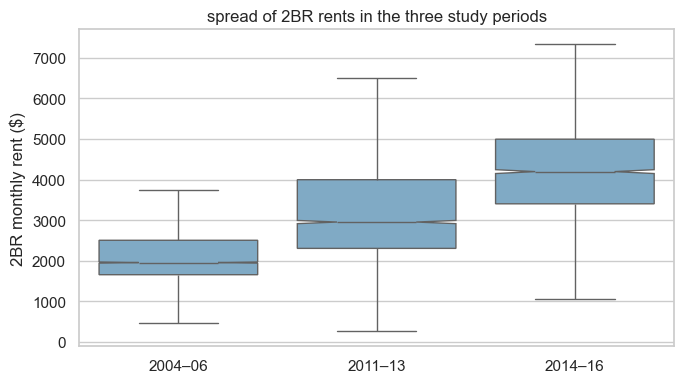

,count,25%,50%,75%
period,,,,
2004–06,9116.0,1650.0,1950.0,2500.0
2011–13,4498.0,2300.0,2950.0,3995.0
2014–16,2727.0,3400.0,4195.0,4995.0


: 

: 

: 

: 

: 

... (3 outputs left out)

: 

: 

: 

: 

In [ ]:
# spread of rent
period_map = lambda y: '2004–06' if 2004 <= y <= 2006 else '2011–13' if 2011 <= y <= 2013 else '2014–16' if 2014 <= y <= 2016 else None
tmp = sf_raw[sf_raw.beds == 2].assign(period=lambda d: d.year.map(period_map)).dropna(subset=['period'])
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=tmp, x='period', y='price', notch=True, showfliers=False, color='#74add1', ax=ax,
            order=['2004–06', '2011–13', '2014–16'])
ax.set_ylabel('2BR monthly rent ($)'); ax.set_xlabel('')
ax.set_title('spread of 2BR rents in the three study periods')
plt.tight_layout(); plt.show()
tmp.groupby('period').price.describe()[['count', '25%', '50%', '75%']].round(0)

### 2.6 Neighborhood coverage

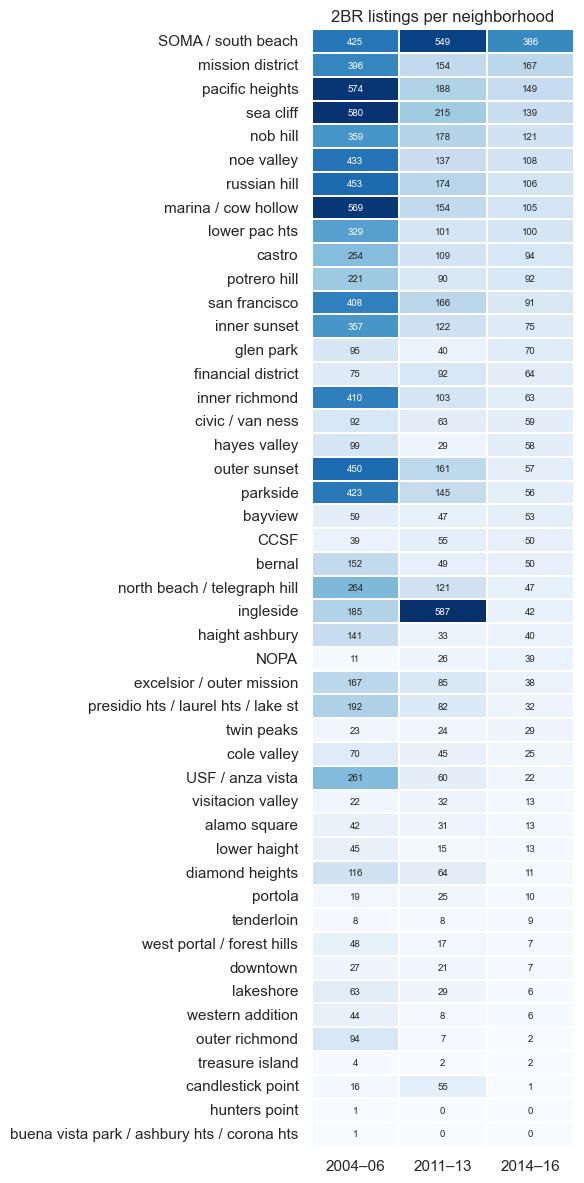

28 of 47 labels have ≥30 2BR listings in both end periods


: 

: 

: 

: 

: 

... (3 outputs left out)

: 

: 

: 

: 

In [ ]:
# 2BR listings per neighborhood and period 
cov = (tmp.pivot_table(index='nhood', columns='period', values='price', aggfunc='size')
          .fillna(0).astype(int)[['2004–06', '2011–13', '2014–16']]
          .sort_values('2014–16', ascending=False))
fig, ax = plt.subplots(figsize=(6, 12))
sns.heatmap(cov, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            annot_kws={'fontsize': 7}, linewidths=.3)
ax.set_title('2BR listings per neighborhood') #cells under 30 are too thin for a stable median
ax.set_ylabel(''); ax.set_xlabel('')
plt.tight_layout(); plt.show()
print(f"{(cov[['2004–06', '2014–16']] >= 30).all(axis=1).sum()} of {len(cov)} labels have ≥30 2BR listings in both end periods")

### 2.7 Square footage, where it exists (2011+)

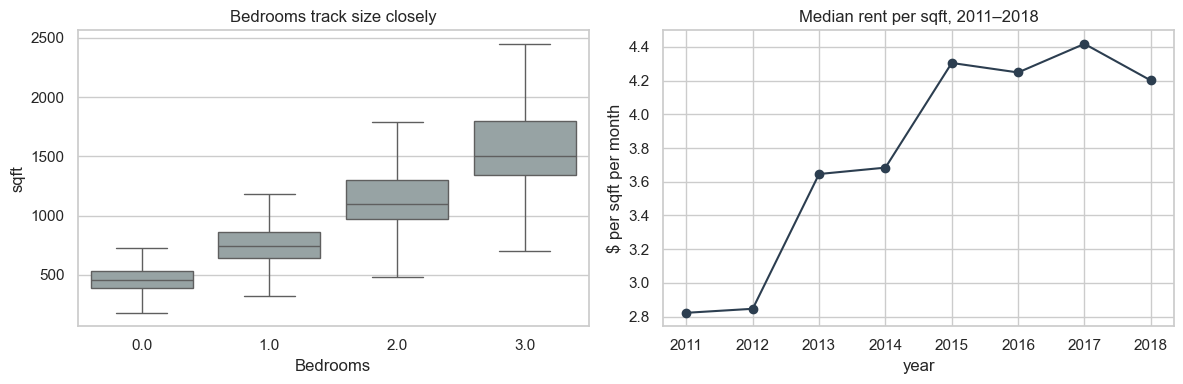

Correlation of beds with sqft (2011+): 0.72


: 

: 

: 

: 

: 

... (3 outputs left out)

: 

: 

: 

: 

In [ ]:
#  unit sizes by bedrooms, 2011 onward
sq = sf_raw[(sf_raw.year >= 2011) & sf_raw.sqft.between(150, 5000) & sf_raw.beds.between(0, 3)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=sq, x='beds', y='sqft', showfliers=False, color='#95a5a6', ax=axes[0])
axes[0].set_title('Bedrooms track size closely'); axes[0].set_xlabel('Bedrooms'); axes[0].set_ylabel('sqft')
sq.assign(ppsf=sq.price / sq.sqft).groupby('year').ppsf.median().plot(marker='o', ax=axes[1], color='#2c3e50')
axes[1].set_title('Median rent per sqft, 2011–2018'); axes[1].set_ylabel('$ per sqft per month')
plt.tight_layout(); plt.show()
print('Correlation of beds with sqft (2011+):', round(sq[['beds', 'sqft']].corr().iloc[0, 1], 2))

### 2.8 Duplicates, rooms for rent, and vague labels

In [ ]:
dup = sf_raw.title.notna() & sf_raw.duplicated(['nhood', 'beds', 'price', 'title'])
print(f"Repeated posts (same neighborhood, beds, price, title): {dup.sum():,} ({dup.mean():.1%} of SF rows)")
print(f"Rooms in shared apartments (room_in_apt = 1): {(sf_raw.room_in_apt == 1).sum():,}")
print(f"Listings with no bedroom count: {sf_raw.beds.isna().sum():,}")
sf_raw.nhood.value_counts().loc[['san francisco', 'CCSF']].to_frame('listings')

Repeated posts (same neighborhood, beds, price, title): 5,268 (9.5% of SF rows)
Rooms in shared apartments (room_in_apt = 1): 123
Listings with no bedroom count: 1,979


,listings
nhood,
san francisco,2329
CCSF,449


: 

: 

: 

: 

... (4 outputs left out)

: 

: 

: 

: 

5,268 SF listings (9.5%) repeat an earlier post exactly: same neighborhood, bedrooms, price and title --> can overweight landlords who repost often

labels "san francisco" (2,329) and "CCSF" (449) aren't precise places, might drop "san francisco" and keep CCSF

## 3. data cleaning

In [14]:
# cleaning function
PERIODS = {'early': (2004, 2006), 'mid': (2011, 2013), 'late': (2014, 2016)}

def clean_rent(rent, trim=True, dedupe=True, min_n=30, verbose=False):
    log = []
    def step(df, label):
        log.append((label, len(df)))
        return df
    d = step(rent, 'All Bay Area listings')
    d = step(d[d.city == 'san francisco'], 'San Francisco only')
    d = step(d[d.nhood != 'san francisco'], "Drop the generic 'san francisco' label")
    d = step(d[d.room_in_apt == 0], 'Drop rooms in shared apartments')
    d = step(d.dropna(subset=['beds']).copy(), 'Drop listings with no bedroom count')
    d['beds_g'] = d.beds.clip(upper=3).astype(int)
    if trim:
        q = d.groupby(['year', 'beds_g']).price
        lo, hi = q.transform(lambda s: s.quantile(.005)), q.transform(lambda s: s.quantile(.995))
        d = step(d[(d.price >= lo) & (d.price <= hi)], 'Trim prices outside 0.5–99.5% (year × bedrooms)')
    if dedupe:
        d = d.sort_values('date')
        d = step(d[~(d.title.notna() & d.duplicated(['nhood', 'beds', 'price', 'title']))], 'Drop reposts')
    d['period'] = 'none'
    for p, (a, b) in PERIODS.items():
        d.loc[d.year.between(a, b), 'period'] = p
    d = step(d[d.period != 'none'], 'Keep 2004–06, 2011–13, 2014–16')
    city_2br = d[d.beds == 2].groupby('period').price.median()       # citywide, before the neighborhood filter
    n2 = d[d.beds == 2].pivot_table(index='nhood', columns='period', values='price', aggfunc='size').fillna(0)
    keep = n2[(n2[['early', 'late']] >= min_n).all(axis=1)].index
    dropped = sorted(set(d.nhood) - set(keep))
    d = step(d[d.nhood.isin(keep)], f'≥{min_n} 2BR listings in 2004–06 and 2014–16')
    return d, city_2br, pd.DataFrame(log, columns=['Step', 'Rows remaining']), dropped

sf, city_2br, clean_log, dropped = clean_rent(rent)
two = sf[sf.beds == 2]
clean_log['Removed'] = (-clean_log['Rows remaining'].diff()).fillna(0).astype(int)
display(clean_log)
print(f"{sf.nhood.nunique()} neighborhoods kept. Dropped ({len(dropped)}): {', '.join(dropped)}")

,Step,Rows remaining,Removed
0,All Bay Area listings,200796,0
1,San Francisco only,55730,145066
2,Drop the generic 'san francisco' label,53401,2329
3,Drop rooms in shared apartments,53281,120
4,Drop listings with no bedroom count,51407,1874
5,Trim prices outside 0.5–99.5% (year × bedrooms),50867,540
6,Drop reposts,45932,4935
7,"Keep 2004–06, 2011–13, 2014–16",40691,5241
8,≥30 2BR listings in 2004–06 and 2014–16,35975,4716


27 neighborhoods kept. Dropped (19): NOPA, USF / anza vista, alamo square, buena vista park / ashbury hts / corona hts, candlestick point, cole valley, diamond heights, downtown, hunters point, lakeshore, lower haight, outer richmond, portola, tenderloin, treasure island, twin peaks, visitacion valley, west portal / forest hills, western addition


55,730 SF listings -->  35,975 remain in 27 neighborhoods. The biggest cuts are reposts (4,935), years outside the three periods (5,241) and thin neighborhoods (4,716)

19 dropped labels include Tenderloin, Visitacion Valley, Portola and Western Addition, several of the city's lowest-income areas

## 4. Analysis

"Lower-income" is approximated by **starting rent**: each neighborhood's median 2BR rent in 2004–06, split into thirds --> proxy for income, not income itself; the file has no income column.

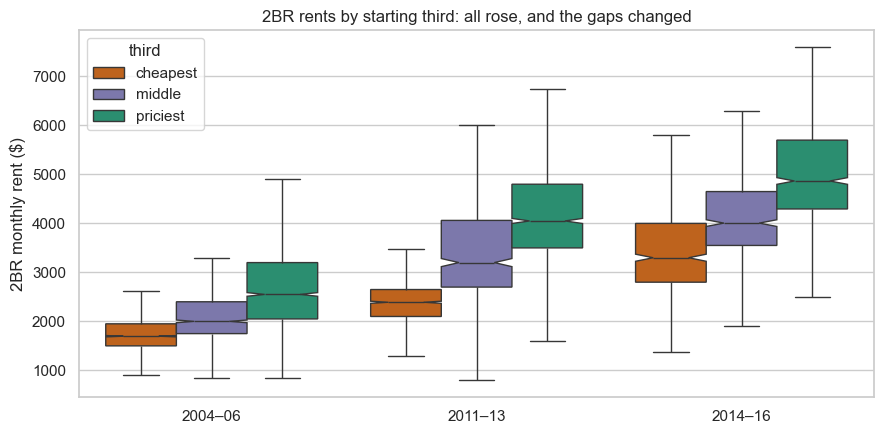

period,early,mid,late,growth_%,n_neighborhoods
third,,,,,
cheapest,1697.0,2390.0,3299.0,94.0,9
middle,2000.0,3200.0,4006.0,100.0,9
priciest,2550.0,4050.0,4866.0,91.0,9


In [15]:
start = two[two.period == 'early'].groupby('nhood').price.median()
third = pd.qcut(start, 3, labels=['cheapest', 'middle', 'priciest']).rename('third')
two = two.join(third, on='nhood')
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=two, x='period', y='price', hue='third', order=['early', 'mid', 'late'],
            notch=True, showfliers=False, palette=THIRD_COLORS, ax=ax)
ax.set_xticklabels(['2004–06', '2011–13', '2014–16']); ax.set_xlabel('')
ax.set_ylabel('2BR monthly rent ($)'); ax.set_title('2BR rents by starting third: all rose, and the gaps changed')
plt.tight_layout(); plt.show()
g = two.pivot_table(index='third', columns='period', values='price', aggfunc='median', observed=True)[['early', 'mid', 'late']]
g['growth_%'] = (g.late / g.early - 1) * 100
g.assign(n_neighborhoods=third.value_counts()).round(0)

All three thirds roughly doubled, and the cheapest did NOT rise fastest. 

Pooling all 2BR listings in each third: cheapest $1,697 → $3,299 (+94%), middle $2,000 → $4,006 (+100%), priciest $2,550 → $4,866 (+91%). gap between cheapest and priciest widened from about $850 to $1,570.

to note: the citywide median rose +113%, more than any of the three thirds --> late listings lean toward expensive downtown (SOMA's share of 2BR listings roughly tripled), so the city's mix got pricier even where rents didn't -->  comparison is made within neighborhoods

## 5. profile table


| Feature | description |
|---|---|
| `rent_early`, `rent_late` | Median 2BR rent in 2004–06 and 2014–16 ($) |
| `growth_pct` | % change in median 2BR rent |
| `small_early`, `small_late` | % of all listings that are studios or 1-bedrooms |
| `small_change` | Change in that share (percentage points) |
| `vol_change` | Change in the neighborhood's share of all SF listings (log ratio); a rough "new supply" signal |

In [16]:
# profile table 
def make_profile(sf):
    two = sf[sf.beds == 2]
    med = two.pivot_table(index='nhood', columns='period', values='price', aggfunc='median')
    small = (sf.assign(small=sf.beds <= 1)
               .pivot_table(index='nhood', columns='period', values='small', aggfunc='mean') * 100)
    vol = sf.groupby(['nhood', 'period']).size().unstack()
    share = vol / vol.sum()
    prof = pd.DataFrame({
        'rent_early':   med['early'],
        'rent_late':    med['late'],
        'growth_pct':   (med['late'] / med['early'] - 1) * 100,
        'small_early':  small['early'],
        'small_late':   small['late'],
        'small_change': small['late'] - small['early'],
        'vol_change':   np.log(share['late'] / share['early']),
    })
    prof['third'] = pd.qcut(prof.rent_early, 3, labels=['cheapest', 'middle', 'priciest'])
    return prof

prof = make_profile(sf)
SEVEN = ['rent_early', 'rent_late', 'growth_pct', 'small_early', 'small_late', 'small_change', 'vol_change']
prof.sort_values('rent_early').round(1)

,rent_early,rent_late,growth_pct,small_early,small_late,small_change,vol_change,third
nhood,,,,,,,,
excelsior / outer mission,1600.0,2500.0,56.2,37.1,44.9,7.8,-0.5,cheapest
sea cliff,1650.0,3125.0,89.4,39.3,33.1,-6.2,-0.3,cheapest
outer sunset,1650.0,3000.0,81.8,33.5,42.5,9.0,-0.7,cheapest
ingleside,1650.0,3085.5,87.0,36.7,44.4,7.7,-0.2,cheapest
parkside,1700.0,2800.0,64.7,31.3,41.9,10.6,-0.8,cheapest
inner sunset,1700.0,3350.0,97.1,50.7,48.0,-2.7,-0.4,cheapest
bayview,1700.0,3295.0,93.8,28.9,37.7,8.8,0.6,cheapest
mission district,1750.0,4295.0,145.4,46.1,41.4,-4.8,0.2,cheapest
inner richmond,1750.0,3295.0,88.3,42.0,36.0,-6.0,-0.7,cheapest


In [21]:
prof[SEVEN].describe().round(1)

,rent_early,rent_late,growth_pct,small_early,small_late,small_change,vol_change
count,27.0,27.0,27.0,27.0,27.0,27.0,27.0
mean,2093.9,4013.1,93.5,48.5,46.2,-2.4,0.0
std,484.6,778.3,22.5,13.9,14.4,8.9,0.6
min,1600.0,2500.0,52.6,28.9,18.4,-18.9,-0.8
25%,1725.0,3295.0,82.9,37.5,37.9,-7.9,-0.3
50%,1999.5,4265.0,93.8,46.1,44.4,-2.7,-0.1
75%,2222.5,4522.5,103.0,56.3,53.2,4.7,0.2
max,3472.5,5299.5,145.4,87.8,78.7,10.6,1.4


: 

: 

: 

: 

: 

: 

: 

: 

: 

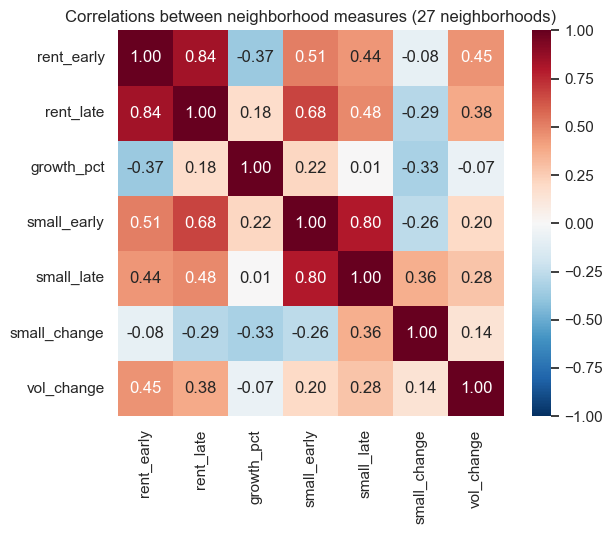

: 

: 

: 

: 

: 

: 

: 

: 

: 

In [23]:
# correlation 
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(prof[SEVEN].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Correlations between neighborhood measures (27 neighborhoods)')
plt.tight_layout(); plt.show()

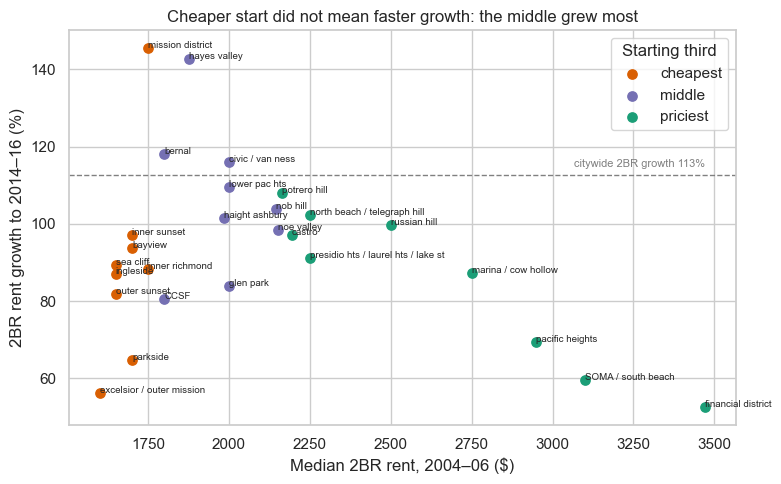

: 

: 

: 

: 

: 

: 

: 

: 

: 

In [ ]:
# rent vs growth
fig, ax = plt.subplots(figsize=(8, 5))
for t, d in prof.groupby('third', observed=True):
    ax.scatter(d.rent_early, d.growth_pct, color=THIRD_COLORS[t], label=t, s=45)
city_growth = (city_2br['late'] / city_2br['early'] - 1) * 100
ax.axhline(city_growth, ls='--', color='grey', lw=1)
ax.text(prof.rent_early.max(), city_growth + 2, f'citywide 2BR growth {city_growth:.0f}%', ha='right', fontsize=8, color='grey')
texts = [ax.text(r.rent_early, r.growth_pct, n, fontsize=7) for n, r in prof.iterrows()]
if adjust_text: adjust_text(texts, ax=ax)
ax.set_xlabel('Median 2BR rent, 2004–06 ($)'); ax.set_ylabel('2BR rent growth to 2014–16 (%)')
ax.set_title('Cheaper start did not mean faster growth: the middle grew most')
ax.legend(title='Starting third'); plt.tight_layout(); plt.show()

**Result.** Across neighborhoods, growth runs from +53% (Financial District) to +145% (Mission). The median neighborhood grew +88% in the cheapest third, +104% in the middle and +91% in the priciest. Only four beat the citywide +113%: Mission, Hayes Valley, Bernal and Civic Center/Van Ness.

The relationship is a **hump, not a line**. Starting rent and growth correlate at −0.37 overall, but that is pulled by Financial District, SOMA and Pacific Heights growing least. The fastest growth is in the low-middle of the range.

**Unit mix.** The cheapest third's studio/1BR share rose (median +7.7 points), but it rose most where rents grew *slowest*: Parkside +10.6, Outer Sunset +9.0, Bayview +8.8. Where rents caught up, the small-unit share often fell (Bernal −18, Haight-Ashbury −19).


## 6. PCA - 7 features, unscaled vs scaled


In [17]:
# all 7 features, unscaled vs scaled 
rows = {}
for name, Z7 in [('unscaled', prof[SEVEN] - prof[SEVEN].mean()),
                 ('scaled',   StandardScaler().fit_transform(prof[SEVEN]))]:
    p = PCA().fit(Z7)
    rows[f'{name}: eigenvalue'] = p.explained_variance_
    rows[f'{name}: share of variance'] = p.explained_variance_ratio_
attempt = pd.DataFrame(rows, index=[f'PC{i+1}' for i in range(7)]).T
display(attempt.style.format('{:.3g}'))
u = PCA().fit(prof[SEVEN] - prof[SEVEN].mean())
print('Unscaled PC1 weights:', dict(zip(SEVEN, u.components_[0].round(2))))

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
unscaled: eigenvalue,7.87e+05,5.42e+04,244,82.4,19.4,0.168,1.4e-30
unscaled: share of variance,0.935,0.0644,0.00029,9.79e-05,2.3e-05,1.99e-07,1.67e-36
scaled: eigenvalue,3.21,1.67,1.16,0.838,0.383,0.0039,3.45e-32
scaled: share of variance,0.442,0.23,0.159,0.115,0.0527,0.000536,4.74e-33


Unscaled PC1 weights: {'rent_early': 0.5, 'rent_late': 0.87, 'growth_pct': 0.0, 'small_early': 0.01, 'small_late': 0.01, 'small_change': -0.0, 'vol_change': 0.0}


Unscaled -->  takes **93.5%** of the variance, and its weights are almost entirely `rent_late` (0.87) and `rent_early` (0.50); every other weight is about 0

scaled --> eigenvalues are 3.21, 1.67, 1.16, 0.84, 0.38, **0.004 and 0.000**

2 components carry nothing because two columns are combinations of others: `small_change` is exactly `small_late − small_early`, and `rent_late` is almost fully determined by `rent_early` and `growth_pct`


## 7. PCA 2: 4 features only


- keep `rent_early` (where it started) and `growth_pct` (how it moved); drop `rent_late` (≈ start × growth)
- keep `small_early` and `small_change`; drop `small_late` (= early + change)
- leave `vol_change` for a sensitivity check (section 11), because it mainly tracks a few new downtown buildings

All four are standardized (mean 0, standard deviation 1), so each gets one vote.

,eigenvalue,share,cumulative
PC1,1.682,0.405,0.405
PC2,1.510,0.364,0.769
PC3,0.704,0.170,0.938
PC4,0.257,0.062,1.000


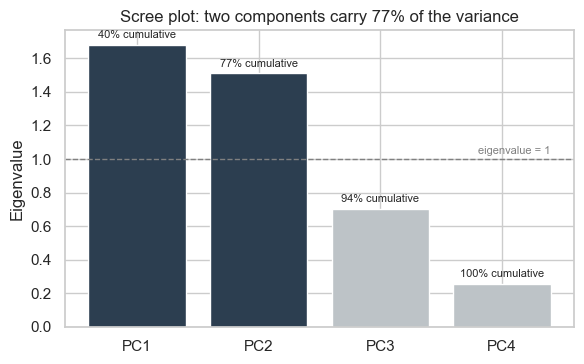

In [18]:
# PCA on 4 standardized features 
FEATS = ['rent_early', 'growth_pct', 'small_early', 'small_change']
NICE = {'rent_early': 'starting 2BR rent', 'growth_pct': '2BR rent growth',
        'small_early': 'starting studio/1BR share', 'small_change': 'change in studio/1BR share'}

def run_pca(prof, feats=FEATS):
    Z = StandardScaler().fit_transform(prof[feats])
    pca = PCA().fit(Z)
    pcs = [f'PC{i+1}' for i in range(len(feats))]
    load = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=feats, columns=pcs)
    # a component's sign is arbitrary: point PC1 with starting rent and PC2 with growth
    flip = np.ones(len(feats))
    flip[0] = np.sign(load.loc['rent_early', 'PC1'])
    flip[1] = np.sign(load.loc['growth_pct', 'PC2'])
    load = load * flip
    scores = pd.DataFrame(pca.transform(Z) * flip, index=prof.index, columns=pcs)
    return Z, pca, load, scores

Z, pca, load, scores = run_pca(prof)
var = pd.DataFrame({'eigenvalue': pca.explained_variance_,
                    'share': pca.explained_variance_ratio_,
                    'cumulative': pca.explained_variance_ratio_.cumsum()}, index=load.columns)
display(var.round(3))

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(var.index, var.eigenvalue, color=['#2c3e50', '#2c3e50', '#bdc3c7', '#bdc3c7'])
ax.axhline(1, ls='--', color='grey', lw=1)
ax.text(3.4, 1.03, 'eigenvalue = 1', ha='right', fontsize=8, color='grey')
for i, (e, c) in enumerate(zip(var.eigenvalue, var.cumulative)):
    ax.text(i, e + 0.04, f'{c:.0%} cumulative', ha='center', fontsize=8)
ax.set_ylabel('Eigenvalue'); ax.set_title(f'Scree plot: two components carry {var.cumulative.iloc[1]:.0%} of the variance')
plt.tight_layout(); plt.show()

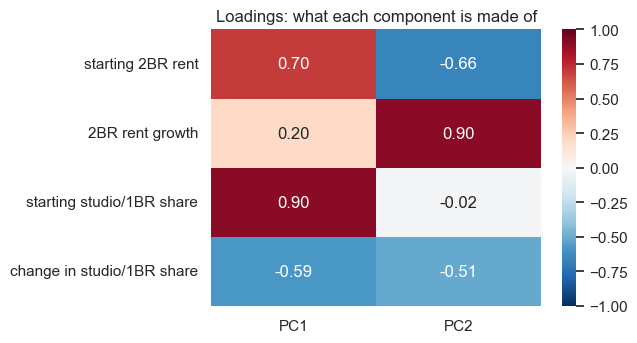

: 

: 

: 

: 

: 

: 

: 

: 

: 

In [ ]:
# correlation 
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(load[['PC1', 'PC2']].rename(index=NICE), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Loadings: what each component is made of')
plt.tight_layout(); plt.show()

The eigenvalues are 1.68, 1.51, 0.70 and 0.26. Two components pass the eigenvalue > 1 rule and together keep **77%** of the variance; we keep two.

**Naming the components from the loadings** (correlations above about 0.5 in size):

- PC1 (40%): high starting studio/1BR share (0.90) and pricier start (0.70), with less shift toward small units since (−0.59). Dense, small-unit neighborhoods.
- PC2 (36%): fast 2BR growth (0.90) from a *lower* starting rent (−0.66), while the small-unit share *fell* (−0.51).

PC2 is the answer to the question in one number. It also says the catch-up went with **fewer** small units, not more.

PC1 and PC2 carry almost the same variance (1.68 vs 1.51), so their order isn't meaningful. We read the two-dimensional map, not a ranking of the axes.

## 8. Evaluation



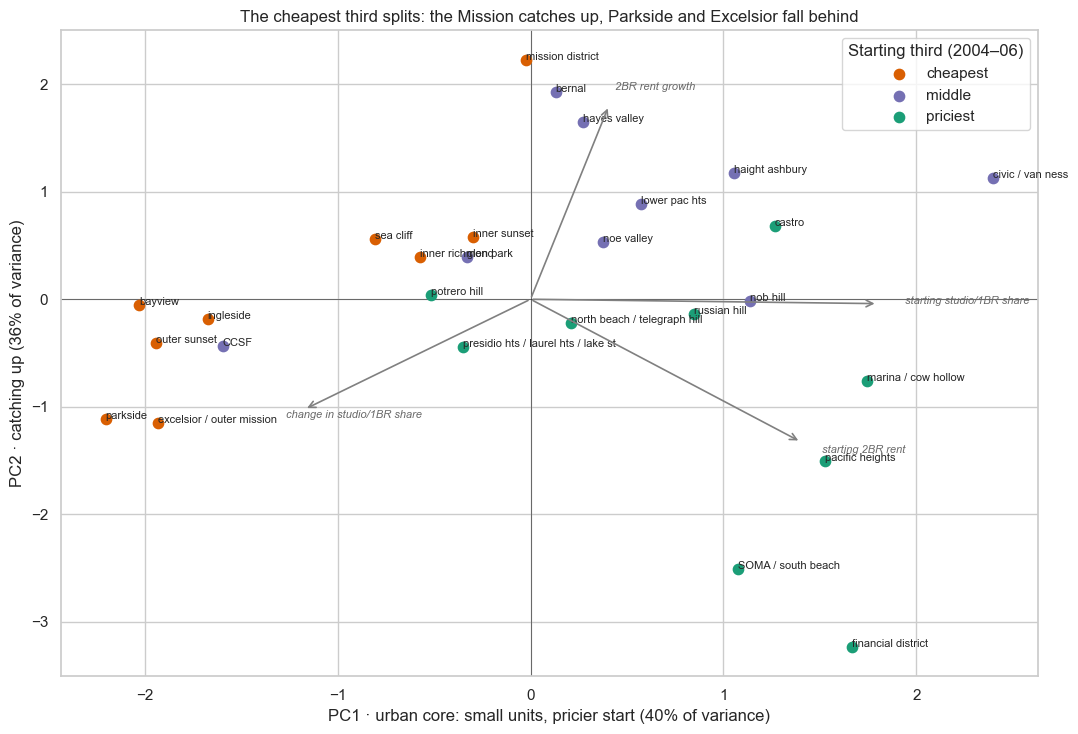

In [19]:
# Each dot is a neighborhood placed by its two component scores, colored by its starting third. 
# Grey arrows show the direction in which each original measure increases. 
# Neighborhoods close together have similar profiles.
fig, ax = plt.subplots(figsize=(11, 7.5))
for t, d in scores.join(prof.third).groupby('third', observed=True):
    ax.scatter(d.PC1, d.PC2, s=55, color=THIRD_COLORS[t], label=t, zorder=3)
texts = [ax.text(r.PC1, r.PC2, n, fontsize=8) for n, r in scores.iterrows()]
for f in FEATS:
    x, y = load.loc[f, 'PC1'] * 2, load.loc[f, 'PC2'] * 2
    ax.annotate('', (x, y), (0, 0), arrowprops=dict(arrowstyle='->', color='grey', lw=1.2))
    texts.append(ax.text(x * 1.08, y * 1.08, NICE[f], color='dimgrey', fontsize=8, style='italic'))
if adjust_text:
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='lightgrey', lw=.6))
ax.axhline(0, color='k', lw=.4); ax.axvline(0, color='k', lw=.4)
ax.set_xlabel(f"PC1 · urban core: small units, pricier start ({var.share['PC1']:.0%} of variance)")
ax.set_ylabel(f"PC2 · catching up ({var.share['PC2']:.0%} of variance)")
ax.set_title('The cheapest third splits: the Mission catches up, Parkside and Excelsior fall behind')
ax.legend(title='Starting third (2004–06)', loc='upper right')
plt.tight_layout(); plt.show()

The cheapest third (orange) is spread from the very top of the map to the bottom. The Mission has the highest "catching up" score of all 27 (2.23), next to middle-third neighbors Bernal, Hayes Valley, Haight-Ashbury and Civic Center/Van Ness. Parkside and Excelsior sit near the bottom, with Bayview, Ingleside, Outer Sunset and CCSF on the far left near or below zero. 

The lowest scores belong to expensive downtown: Financial District (−3.23), SOMA (−2.51), Pacific Heights (−1.50), places that started high and grew least.

the thirds hide a split, and rent pressure concentrated in a band of central neighborhoods, not in the cheapest third as a whole.

In [20]:
# correlations between component scores and the original measures
check = pd.concat([scores[['PC1', 'PC2']], prof[SEVEN]], axis=1).corr().loc[SEVEN, ['PC1', 'PC2']]
check.round(2)

,PC1,PC2
rent_early,0.69,-0.65
rent_late,0.85,-0.17
growth_pct,0.20,0.88
small_early,0.88,-0.02
small_late,0.50,-0.33
small_change,-0.57,-0.50
vol_change,0.24,-0.29


In [21]:
# neighborhoods ranked by PC2 ('catching up') + raw numbers 
ranked = (scores[['PC1', 'PC2']].join(prof[['third', 'rent_early', 'growth_pct', 'small_change']])
          .sort_values('PC2', ascending=False))
display(ranked.round(2))
print('Median PC2 by starting third:')
print(ranked.groupby('third', observed=True).PC2.median().round(2).to_string())

,PC1,PC2,third,rent_early,growth_pct,small_change
nhood,,,,,,
mission district,-0.02,2.23,cheapest,1750.0,145.43,-4.76
bernal,0.13,1.92,middle,1800.0,118.06,-18.36
hayes valley,0.27,1.65,middle,1875.0,142.67,2.25
haight ashbury,1.05,1.17,middle,1985.0,101.46,-18.92
civic / van ness,2.40,1.13,middle,2000.0,116.12,-9.10
lower pac hts,0.57,0.88,middle,1999.5,109.55,-7.62
castro,1.27,0.69,priciest,2195.0,97.04,-16.86
inner sunset,-0.30,0.57,cheapest,1700.0,97.06,-2.66
sea cliff,-0.80,0.56,cheapest,1650.0,89.39,-6.20


Median PC2 by starting third:
third
cheapest   -0.06
middle      0.88
priciest   -0.44


map matches the raw numbers. PC2 correlates 0.88 with growth; PC1 correlates 0.88 with the starting small-unit share and 0.85 with late rent. The top of the PC2 ranking (Mission, Bernal, Hayes Valley, Civic Center) is exactly the four neighborhoods that beat citywide growth in section 5.

Median PC2 by starting third: middle +0.88, cheapest −0.06, priciest −0.44 -->  middle third is the one catching up.

In [22]:
# leave-one-out stability
base = PCA(2).fit(Z).components_
rows = []
for nh in prof.index:
    ci = PCA(2).fit(StandardScaler().fit_transform(prof.drop(nh)[FEATS])).components_
    rows.append({'dropped': nh,
                 'plane_tilt_deg': np.degrees(subspace_angles(base.T, ci.T)).max(),
                 'PC1_match': abs(ci[0] @ base[0]),
                 'PC2_match': abs(ci[1] @ base[1])})
stab = pd.DataFrame(rows).set_index('dropped')
display(stab.sort_values('plane_tilt_deg', ascending=False).head(6).round(2))
print(f"Largest plane tilt: {stab.plane_tilt_deg.max():.1f}°  ·  weakest axis match: {stab[['PC1_match', 'PC2_match']].min().min():.2f}")

,plane_tilt_deg,PC1_match,PC2_match
dropped,,,
financial district,6.51,0.98,0.97
bernal,6.29,1.00,0.99
civic / van ness,5.85,0.92,0.91
pacific heights,4.27,0.96,0.96
hayes valley,3.39,0.99,0.99
excelsior / outer mission,3.24,0.73,0.73


Largest plane tilt: 6.5°  ·  weakest axis match: 0.73


dropping any single neighborhood tilts the PC1–PC2 plane by at most 6.5° (when the Financial District is dropped) --> stable

weakest axis match is 0.73 (dropping Excelsior): the two axes can rotate a little inside the plane, as expected when their eigenvalues are close. that is one more reason to read neighborhoods' positions on the map rather than argue about which axis comes first.

In [25]:
# growth relative to the citywide median 
city_growth = (city_2br['late'] / city_2br['early'] - 1) * 100
prof['growth_vs_city'] = prof.growth_pct - city_growth
print(f'Citywide median 2BR rent: ${city_2br["early"]:,.0f} (2004–06) → ${city_2br["late"]:,.0f} (2014–16), +{city_growth:.0f}%')
display(prof.groupby('third', observed=True).growth_vs_city.describe()[['count', 'min', '50%', 'max']].round(1))
print('Neighborhoods that beat the citywide growth:',
      ', '.join(prof[prof.growth_vs_city > 0].sort_values('growth_vs_city', ascending=False).index))
same = np.allclose(StandardScaler().fit_transform(prof[['growth_pct']]),
                   StandardScaler().fit_transform(prof[['growth_vs_city']]))
print('Does indexing change the standardized PCA input?', 'No' if same else 'Yes')

Citywide median 2BR rent: $1,975 (2004–06) → $4,200 (2014–16), +113%


,count,min,50%,max
third,,,,
cheapest,9.0,-56.4,-24.4,32.8
middle,9.0,-32.2,-8.9,30.0
priciest,9.0,-60.0,-21.5,-4.8


Neighborhoods that beat the citywide growth: mission district, hayes valley, bernal, civic / van ness
Does indexing change the standardized PCA input? No


In [26]:
# growth ranking with rent per bedroom
ppb = (sf.assign(ppb=sf.price / sf.beds.clip(lower=1))
         .pivot_table(index='nhood', columns='period', values='ppb', aggfunc='median'))
growth_ppb = (ppb['late'] / ppb['early'] - 1) * 100
r_p = np.corrcoef(prof.growth_pct, growth_ppb[prof.index])[0, 1]
rho = spearmanr(prof.growth_pct, growth_ppb[prof.index]).correlation
print(f'2BR growth vs rent-per-bedroom growth across neighborhoods: Pearson r = {r_p:.2f}, rank correlation = {rho:.2f}')

2BR growth vs rent-per-bedroom growth across neighborhoods: Pearson r = 0.81, rank correlation = 0.80


In [27]:
# sensitivity 
def finding(scores):
    q_hi, q_lo, med = scores.PC2.quantile(.75), scores.PC2.quantile(.25), scores.PC2.median()
    get = lambda n: scores.PC2.get(n, np.nan)
    return (get('mission district') >= q_hi,
            get('parkside') <= q_lo and get('excelsior / outer mission') <= q_lo,
            get('outer sunset') < med)

variants = {}
def add(label, prof_v, feats=FEATS):
    _, p, _, s = run_pca(prof_v, feats)
    common = s.index.intersection(scores.index)
    mission_top, lag_bottom, os_low = finding(s)
    variants[label] = {'neighborhoods': len(prof_v),
                       'variance in PC1+PC2': f'{p.explained_variance_ratio_[:2].sum():.0%}',
                       'PC2 rank agreement with main': round(spearmanr(s.loc[common, 'PC2'], scores.loc[common, 'PC2']).correlation, 2),
                       'Mission in top quarter of PC2': mission_top,
                       'Parkside & Excelsior in bottom quarter': lag_bottom,
                       'Outer Sunset below median': os_low}

add('Main (4 features)', prof)
add('Without CCSF (vague label)', prof.drop('CCSF'))
add('Add listing-volume change', prof, FEATS + ['vol_change'])
add('No price trim, no dedupe', make_profile(clean_rent(rent, trim=False, dedupe=False)[0]))
add('Stricter rule: ≥50 2BR listings', make_profile(clean_rent(rent, min_n=50)[0]))
pd.DataFrame(variants).T

,neighborhoods,variance in PC1+PC2,PC2 rank agreement with main,Mission in top quarter of PC2,Parkside & Excelsior in bottom quarter,Outer Sunset below median
Main (4 features),27,77%,1.0,True,True,True
Without CCSF (vague label),26,76%,0.98,True,True,True
Add listing-volume change,27,67%,0.84,True,True,True
"No price trim, no dedupe",27,77%,0.86,True,True,True
Stricter rule: ≥50 2BR listings,19,75%,0.94,True,False,True


**Citywide index.** The city's median 2BR rose +113% ($1,975 → $4,200). Relative to that, the median neighborhood fell behind by 24 points in the cheapest third, 9 in the middle and 22 in the priciest. Indexing subtracts the same number from every neighborhood, so the standardized PCA is unchanged; it changes how we read the charts, not the map.

**Unit size.** Growth measured with rent per bedroom agrees closely with 2BR growth (r = 0.81, rank correlation 0.80). The ranking isn't an artifact of using 2-bedrooms.

**Sensitivity.** The Mission stays in the top quarter of "catching up" in all five versions, and Outer Sunset stays below the median in all five. Parkside and Excelsior stay in the bottom quarter in four of five. The exception is the stricter 50-listing rule, which **drops Excelsior** (only 38 two-bedroom listings in 2014–16) rather than moving it. Adding listing-volume change lowers the variance in two components to 67% but keeps the ranking similar (0.84).